Saving big-lion-lying-savannah-grass-landscape-characteristic-trees-plain-hills-background-35172905.webp to big-lion-lying-savannah-grass-landscape-characteristic-trees-plain-hills-background-35172905.webp


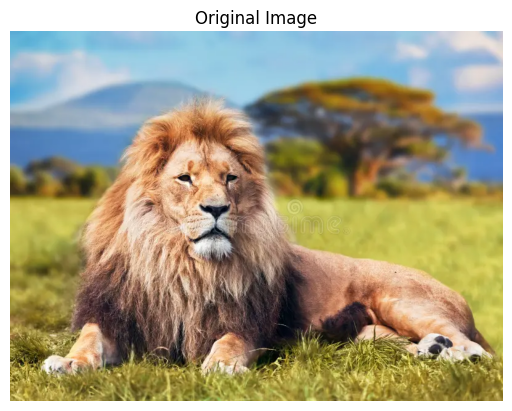

In [1]:
# Step 1: Import the required libraries and load an image

import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = cv2.imread(image_path)

if image is None:
    print("Error: Image not found.")
else:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.imshow(image_rgb)
    plt.title("Original Image")
    plt.axis("off")
    plt.show()

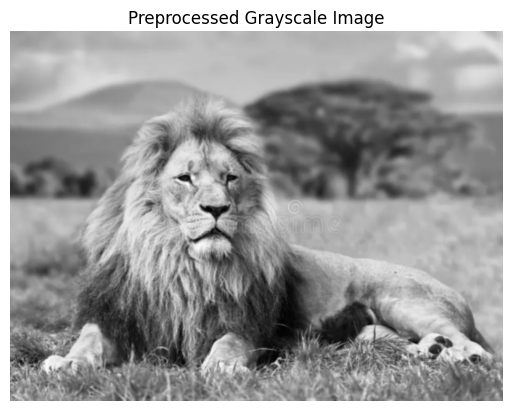

In [2]:
# Step 2: Convert the image into grayscale and perform preprocessing

gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

gray_image = cv2.GaussianBlur(gray_image, (3, 3), 0)

plt.imshow(gray_image, cmap="gray")
plt.title("Preprocessed Grayscale Image")
plt.axis("off")
plt.show()

In [3]:
# Step 3: Apply SIFT to detect keypoints and compute descriptors

sift = cv2.SIFT_create()

keypoints, descriptors = sift.detectAndCompute(gray_image, None)

print("Number of SIFT Keypoints:", len(keypoints))
print("Descriptor Shape:", descriptors.shape)

Number of SIFT Keypoints: 2783
Descriptor Shape: (2783, 128)


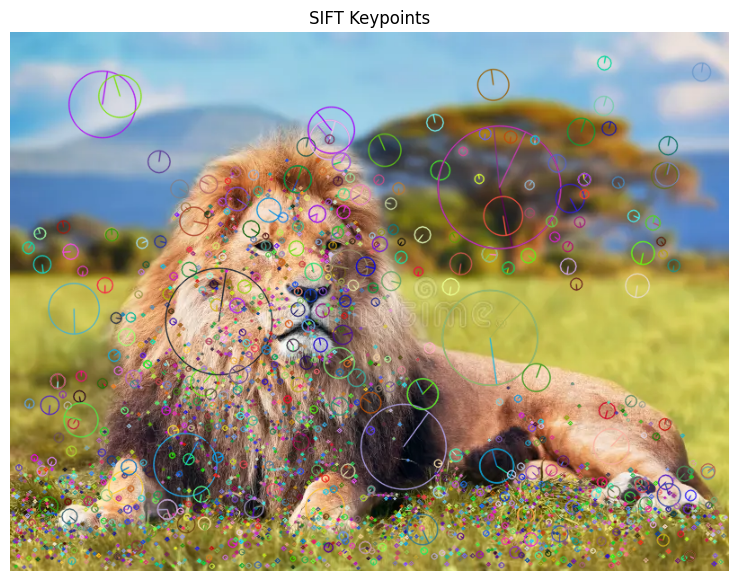

In [4]:
# Step 4: Visualize the detected SIFT keypoints

sift_image = cv2.drawKeypoints(
    image,
    keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(sift_image, cv2.COLOR_BGR2RGB))
plt.title("SIFT Keypoints")
plt.axis("off")
plt.show()

In [5]:
# Step 5: Extract HOG features

from skimage.feature import hog

hog_features, hog_image = hog(
    gray_image,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

print("HOG Feature Length:", len(hog_features))

HOG Feature Length: 263736


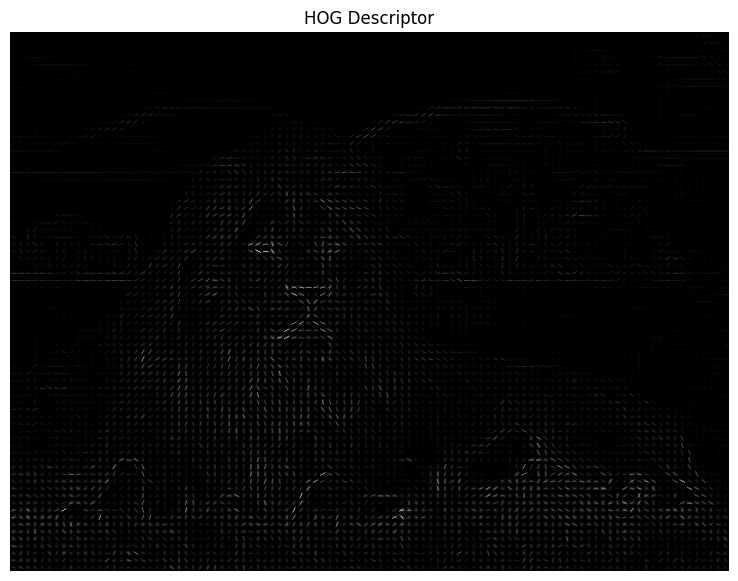

In [6]:
# Step 6: Visualize the HOG descriptor

plt.figure(figsize=(10, 7))
plt.imshow(hog_image, cmap="gray")
plt.title("HOG Descriptor")
plt.axis("off")
plt.show()

In [7]:
# Step 7: Compare SIFT keypoints and HOG descriptors

print("SIFT Keypoints:", len(keypoints))
print("SIFT Descriptor Shape:", descriptors.shape)
print("HOG Feature Length:", len(hog_features))

print("\nSIFT provides scale and rotation invariant local features.")
print("HOG describes local gradient orientations and is mainly useful for shape and object detection.")
print("SIFT generally requires more computational processing than HOG.")

SIFT Keypoints: 2783
SIFT Descriptor Shape: (2783, 128)
HOG Feature Length: 263736

SIFT provides scale and rotation invariant local features.
HOG describes local gradient orientations and is mainly useful for shape and object detection.
SIFT generally requires more computational processing than HOG.


Saving EAGLE.jpg to EAGLE.jpg


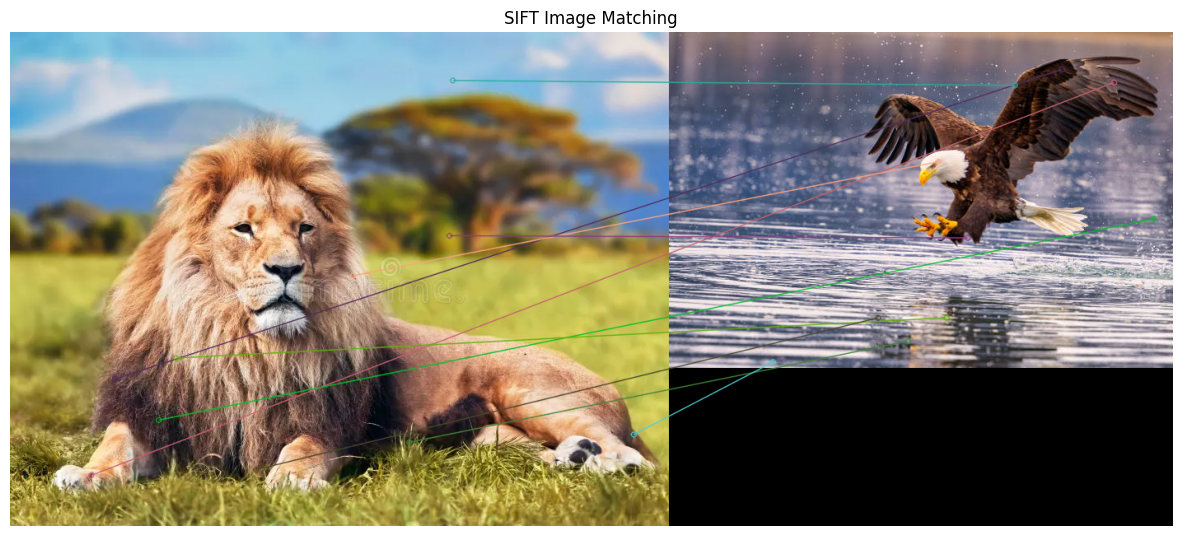

Total Good Matches: 10


In [8]:
# Step 8: Perform image matching using SIFT

uploaded = files.upload()

image_path_2 = list(uploaded.keys())[0]

image2 = cv2.imread(image_path_2)

gray_image2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

keypoints2, descriptors2 = sift.detectAndCompute(gray_image2, None)

bf = cv2.BFMatcher()

matches = bf.knnMatch(descriptors, descriptors2, k=2)

good_matches = []

for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

matched_image = cv2.drawMatches(
    image,
    keypoints,
    image2,
    keypoints2,
    good_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(15, 8))
plt.imshow(cv2.cvtColor(matched_image, cv2.COLOR_BGR2RGB))
plt.title("SIFT Image Matching")
plt.axis("off")
plt.show()

print("Total Good Matches:", len(good_matches))

In [9]:
# Step 9: Evaluate SIFT and HOG

print("SIFT Strengths:")
print("- Scale invariant")
print("- Rotation invariant")
print("- Effective for image matching and object recognition")

print("\nSIFT Limitations:")
print("- Computationally expensive")
print("- Requires more processing time")

print("\nHOG Strengths:")
print("- Effective for shape and object detection")
print("- Simple gradient-based representation")
print("- Useful for pedestrian detection")

print("\nHOG Limitations:")
print("- Less robust to large changes in scale and rotation")
print("- Sensitive to changes in illumination and object appearance")

SIFT Strengths:
- Scale invariant
- Rotation invariant
- Effective for image matching and object recognition

SIFT Limitations:
- Computationally expensive
- Requires more processing time

HOG Strengths:
- Effective for shape and object detection
- Simple gradient-based representation
- Useful for pedestrian detection

HOG Limitations:
- Less robust to large changes in scale and rotation
- Sensitive to changes in illumination and object appearance


In [10]:
# Step 10: Save the feature extraction results

cv2.imwrite("sift_keypoints.jpg", sift_image)
cv2.imwrite("hog_visualization.jpg", np.uint8(hog_image * 255))
cv2.imwrite("sift_matching.jpg", matched_image)

print("SIFT and HOG feature extraction completed successfully.")
print("Result images have been saved.")

SIFT and HOG feature extraction completed successfully.
Result images have been saved.
